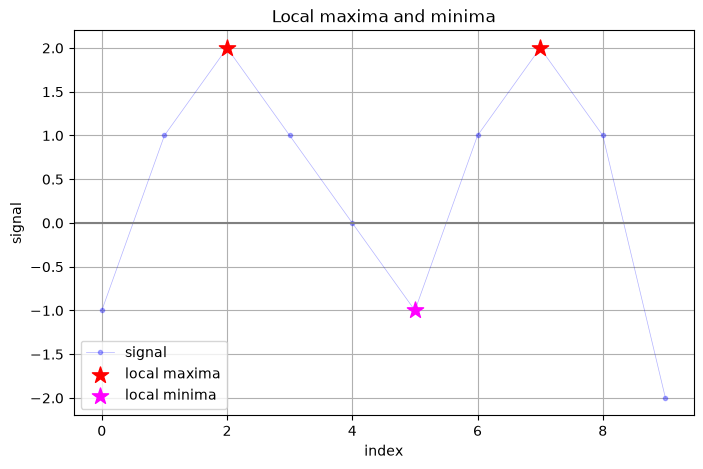

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def find_zero_crossings(signal):
    """
    Trouve les passages par zéro d'un signal 1D.

    Entrée :
        signal (np.ndarray) : signal 1D
    Sorties :
        positive (list) : indices où le signal passe de négatif à positif
        negative (list) : indices où le signal passe de positif à négatif
    """
    positive = []
    negative = []

    # On parcourt chaque paire de points consécutifs du signal
    for i in range(len(signal) - 1):
        # Passage de négatif à positif (ou nul)
        if signal[i] < 0 and signal[i + 1] >= 0:
            positive.append(i + 1)
        # Passage de positif (ou nul) à négatif
        elif signal[i] >= 0 and signal[i + 1] < 0:
            negative.append(i + 1)

    return positive, negative


def find_extrema(signal):
    """
    Trouve les maxima et minima locaux d'un signal 1D.

    Entrée :
        signal (np.ndarray) : signal 1D
    Sorties :
        maxima (list) : indices des maxima locaux
        minima (list) : indices des minima locaux
    """
    # Dérivée discrète : différence entre deux points consécutifs
    derivative = np.diff(signal)
    maxima = []
    minima = []

    for i in range(1, len(derivative)):
        # La dérivée passe de positive à négative : maximum local
        if derivative[i - 1] > 0 and derivative[i] < 0:
            maxima.append(i)
        # La dérivée passe de négative à positive : minimum local
        elif derivative[i - 1] < 0 and derivative[i] > 0:
            minima.append(i)

    return maxima, minima


def plot_signal(signal):
    """
    Trace le signal en fonction de son indice (sans afficher).

    Entrée :
        signal (np.ndarray) : signal 1D
    Sortie :
        aucune (ajoute la courbe à la figure courante)
    """
    index = np.arange(len(signal))
    plt.plot(index, signal, color="blue", marker=".", linewidth=0.5, alpha=0.3, label="signal")


def plot_points(signal, points, label, color):
    """
    Ajoute des points remarquables au graphique (sans afficher).

    Entrées :
        signal (np.ndarray) : signal 1D
        points (list) : indices des points à marquer
        label (str) : nom affiché dans la légende
        color (str) : couleur des marqueurs
    Sortie :
        aucune (ajoute les points à la figure courante)
    """
    if points:
        plt.scatter(
            points,
            signal[points],
            color=color,
            marker="*",
            s=150,
            label=label,
            zorder=3,
        )


def display_figure(title="Local maxima and minima"):
    """
    Met en forme la figure courante et l'affiche.

    Entrée :
        title (str) : titre du graphique
    Sortie :
        aucune (affiche le graphique)
    """
    plt.axhline(0, color="gray")
    plt.grid(True)
    plt.xlabel("index")
    plt.ylabel("signal")
    plt.title(title)
    plt.legend()
    plt.show()


# Signal de référence
signal = np.array([-1, 1, 2, 1, 0, -1, 1, 2, 1, -2])

# Trouver les points remarquables
maxima, minima = find_extrema(signal)

# Tracer le signal et les extrema
plt.figure(figsize=(8, 5))
plot_signal(signal)
plot_points(signal, maxima, "local maxima", "red")
plot_points(signal, minima, "local minima", "magenta")
display_figure()